In [1]:
import torch
import numpy as np
from sklearn.datasets import load_diabetes, load_iris, load_wine
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, MSELoss, CrossEntropyLoss, Dropout
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR

import matplotlib.pyplot as plt


In [2]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).float()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        int(idx)
        return self._x[idx], self._y[idx]

In [3]:
def train_model_class(features, targets, skf, batch, epochs, criterion, exp=False):
    accuracy_scores = []
    f1_scores = []
    # alteração aq
    folds_loss = []
    folds_acc = []

    for i, (train_index, test_index) in enumerate(skf.split(features, targets)):
        print(f"Treinando modelo ----- SKFold {i + 1}")
        train_data = MyDataset(features[train_index], targets[train_index])
        train_loader = DataLoader(train_data, batch_size=batch)

        model= build_model() 
        optmizer = Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

        # alteração aq
        epoch_loss = []
        epoch_acc = []

        for i_epochs in range(epochs):    
            model.train()

            # alteração aq
            batches_loss = []
            batches_acc = []

            for x, y in train_loader:
                y = y.long()
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()

                # alteração aq
                batches_loss.append(loss.item())
                batches_acc.append(accuracy_score(y, torch.argmax(output, dim=1).cpu().numpy()))
            # alteração aq    
            epoch_loss.append(np.mean(batches_loss))
            epoch_acc.append(np.mean(batches_acc))
        # alteração aq
        folds_loss.append(epoch_loss)
        folds_acc.append(epoch_acc)

        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(features[test_index]).float()
            y_true = targets[test_index]

            outputs = model(x_test_tensor)
            result = torch.argmax(outputs, dim=1).cpu().numpy()
         
            accuracy = accuracy_score(y_true, result)
            f1 = f1_score(y_true, result, average="macro")
            confusion = confusion_matrix(y_true, result)

            accuracy_scores.append(accuracy)
            f1_scores.append(f1)
            
            print(f"Accuracy: {accuracy}")
            print(f"f1: {f1}")
            print(f"confusion: \n{confusion}")

    print(f"\nResultado modelo ----- Accuracy: {np.mean(accuracy_scores)}, f1: {np.mean(f1_scores)}")
    
    # alteração aq
    return folds_loss, folds_acc

In [4]:
dataset = load_wine()
features = dataset.data
targets = dataset.target
scaler = StandardScaler()
features = scaler.fit_transform(features)

In [5]:
def build_model():
    return Sequential(
        Linear(13, 64),
        ReLU(),
        torch.nn.Dropout(0.2),
        Linear(64,16),
        ReLU(),
        Linear(16, 3)
)

In [6]:
criterion = CrossEntropyLoss()
max_epochs = 300
batch = 8
skf = StratifiedKFold(n_splits=5, shuffle=True)

In [7]:
def plot_loss(folds_loss, folds_acc):
    folds_acc = folds_acc * 100
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        x = np.linspace(0, len(fold_l), len(fold_l))
        ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        ax1.set_ylim(0, 0.2)
        ax2 = ax1.twinx()
        ax2.plot(x, folds_acc[idx], color="blue", label="Acc")
        ax2.set_ylabel("Acurácia")
        ax2.set_ylim(0.8, 1.1)
        ax2.grid()
        fig.legend()
        fig.show()

In [8]:
folds_loss, folds_acc = train_model_class(features, targets, skf, batch, max_epochs, criterion, True)

Treinando modelo ----- SKFold 1
Accuracy: 0.9722222222222222
f1: 0.9709618874773139
confusion: 
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
Treinando modelo ----- SKFold 2
Accuracy: 0.9722222222222222
f1: 0.9717813051146384
confusion: 
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]
Treinando modelo ----- SKFold 3
Accuracy: 0.9722222222222222
f1: 0.9717813051146384
confusion: 
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]
Treinando modelo ----- SKFold 4
Accuracy: 0.9428571428571428
f1: 0.9391534391534391
confusion: 
[[12  0  0]
 [ 0 13  1]
 [ 0  1  8]]
Treinando modelo ----- SKFold 5
Accuracy: 1.0
f1: 1.0
confusion: 
[[11  0  0]
 [ 0 15  0]
 [ 0  0  9]]

Resultado modelo ----- Accuracy: 0.9719047619047618, f1: 0.9707355873720059


C:\Users\Aluno\AppData\Local\Temp\ipykernel_71828\3649337085.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


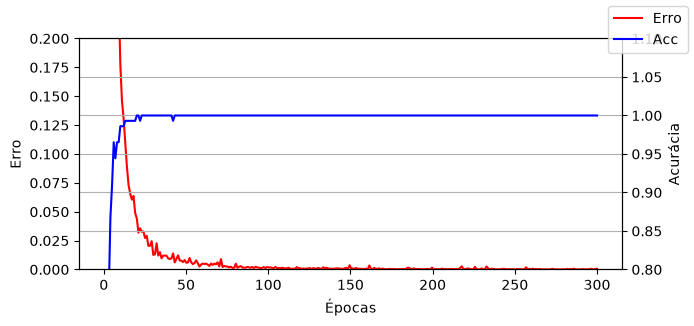

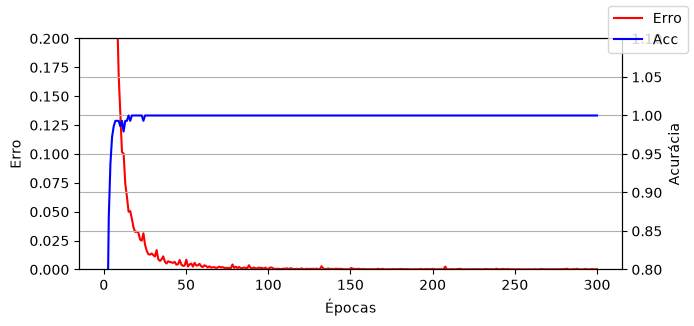

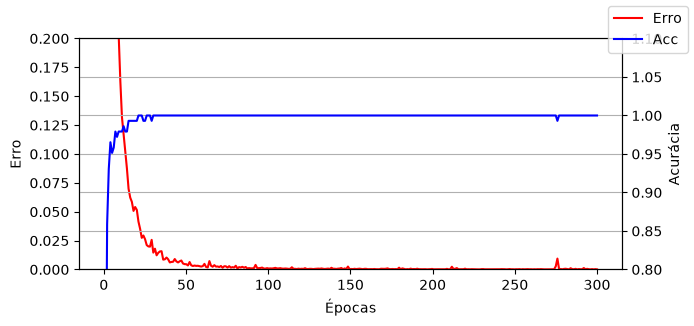

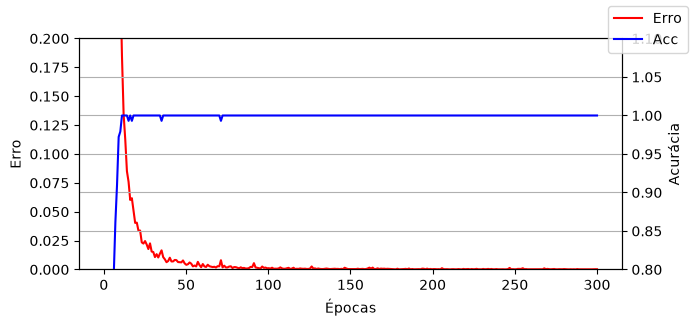

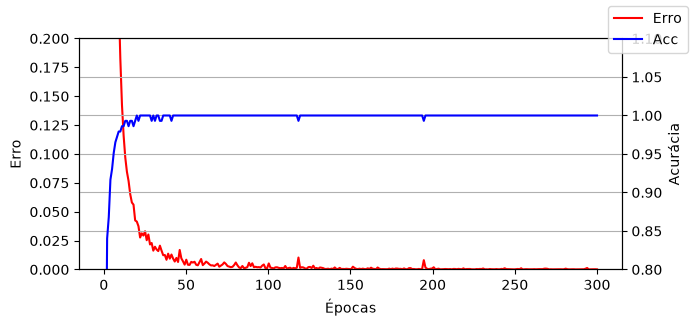

In [9]:
plot_loss(folds_loss, folds_acc)